GENERATIVE AI LABORATORY - EXPERIMENT 5
T5 ENGLISH-TO-FRENCH TRANSLATION AND DATA VISUALIZATION
Device being used: cpu

Loading T5 tokenizer and model...


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

T5 model loaded successfully!

GENERATED TRANSLATIONS AND SENTENCE-LEVEL BLEU SCORES

Sentence 1
English    : Hello, how are you?
Generated  : Bonjour, comment êtes-vous?
Reference  : Bonjour, comment allez-vous ?
BLEU Score : 42.73

Sentence 2
English    : I love artificial intelligence.
Generated  : J'aime l'intelligence artificielle.
Reference  : J'aime l'intelligence artificielle.
BLEU Score : 100.0

Sentence 3
English    : The weather is very good today.
Generated  : Le temps est très bon aujourd'hui.
Reference  : Le temps est très beau aujourd'hui.
BLEU Score : 48.89

Sentence 4
English    : I am a student of computer science.
Generated  : Je suis un étudiant en informatique.
Reference  : Je suis étudiante en informatique.
BLEU Score : 30.74

Sentence 5
English    : Machine learning is changing the world.
Generated  : L'apprentissage des machines change le monde.
Reference  : L'apprentissage automatique change le monde.
BLEU Score : 43.47

Sentence 6
English    : Technology helps

,Sentence No.,English Input,Generated French,Reference French,BLEU Score,Generated Length,Reference Length
0,1,"Hello, how are you?","Bonjour, comment êtes-vous?","Bonjour, comment allez-vous ?",42.73,3,4
1,2,I love artificial intelligence.,J'aime l'intelligence artificielle.,J'aime l'intelligence artificielle.,100.00,3,3
2,3,The weather is very good today.,Le temps est très bon aujourd'hui.,Le temps est très beau aujourd'hui.,48.89,6,6
3,4,I am a student of computer science.,Je suis un étudiant en informatique.,Je suis étudiante en informatique.,30.74,6,5
4,5,Machine learning is changing the world.,L'apprentissage des machines change le monde.,L'apprentissage automatique change le monde.,43.47,6,5
5,6,Technology helps people communicate.,La technologie aide les gens à communiquer.,La technologie aide les gens à communiquer.,100.00,7,7
6,7,The sun rises in the east.,Le soleil s'élève à l'est.,Le soleil se lève à l'est.,32.16,5,6
7,8,Education is important for everyone.,L'éducation est importante pour tous.,L'éducation est importante pour tout le monde.,38.50,5,7



BLEU SCORE STATISTICAL ANALYSIS
Average BLEU Score      : 54.56
Minimum BLEU Score      : 30.74
Maximum BLEU Score      : 100.00
Standard Deviation      : 26.81
Corpus BLEU Score       : 54.69

Highest-scoring sentence:
English: I love artificial intelligence.
French : J'aime l'intelligence artificielle.
Score  : 100.0

Lowest-scoring sentence:
English: I am a student of computer science.
French : Je suis un étudiant en informatique.
Score  : 30.74


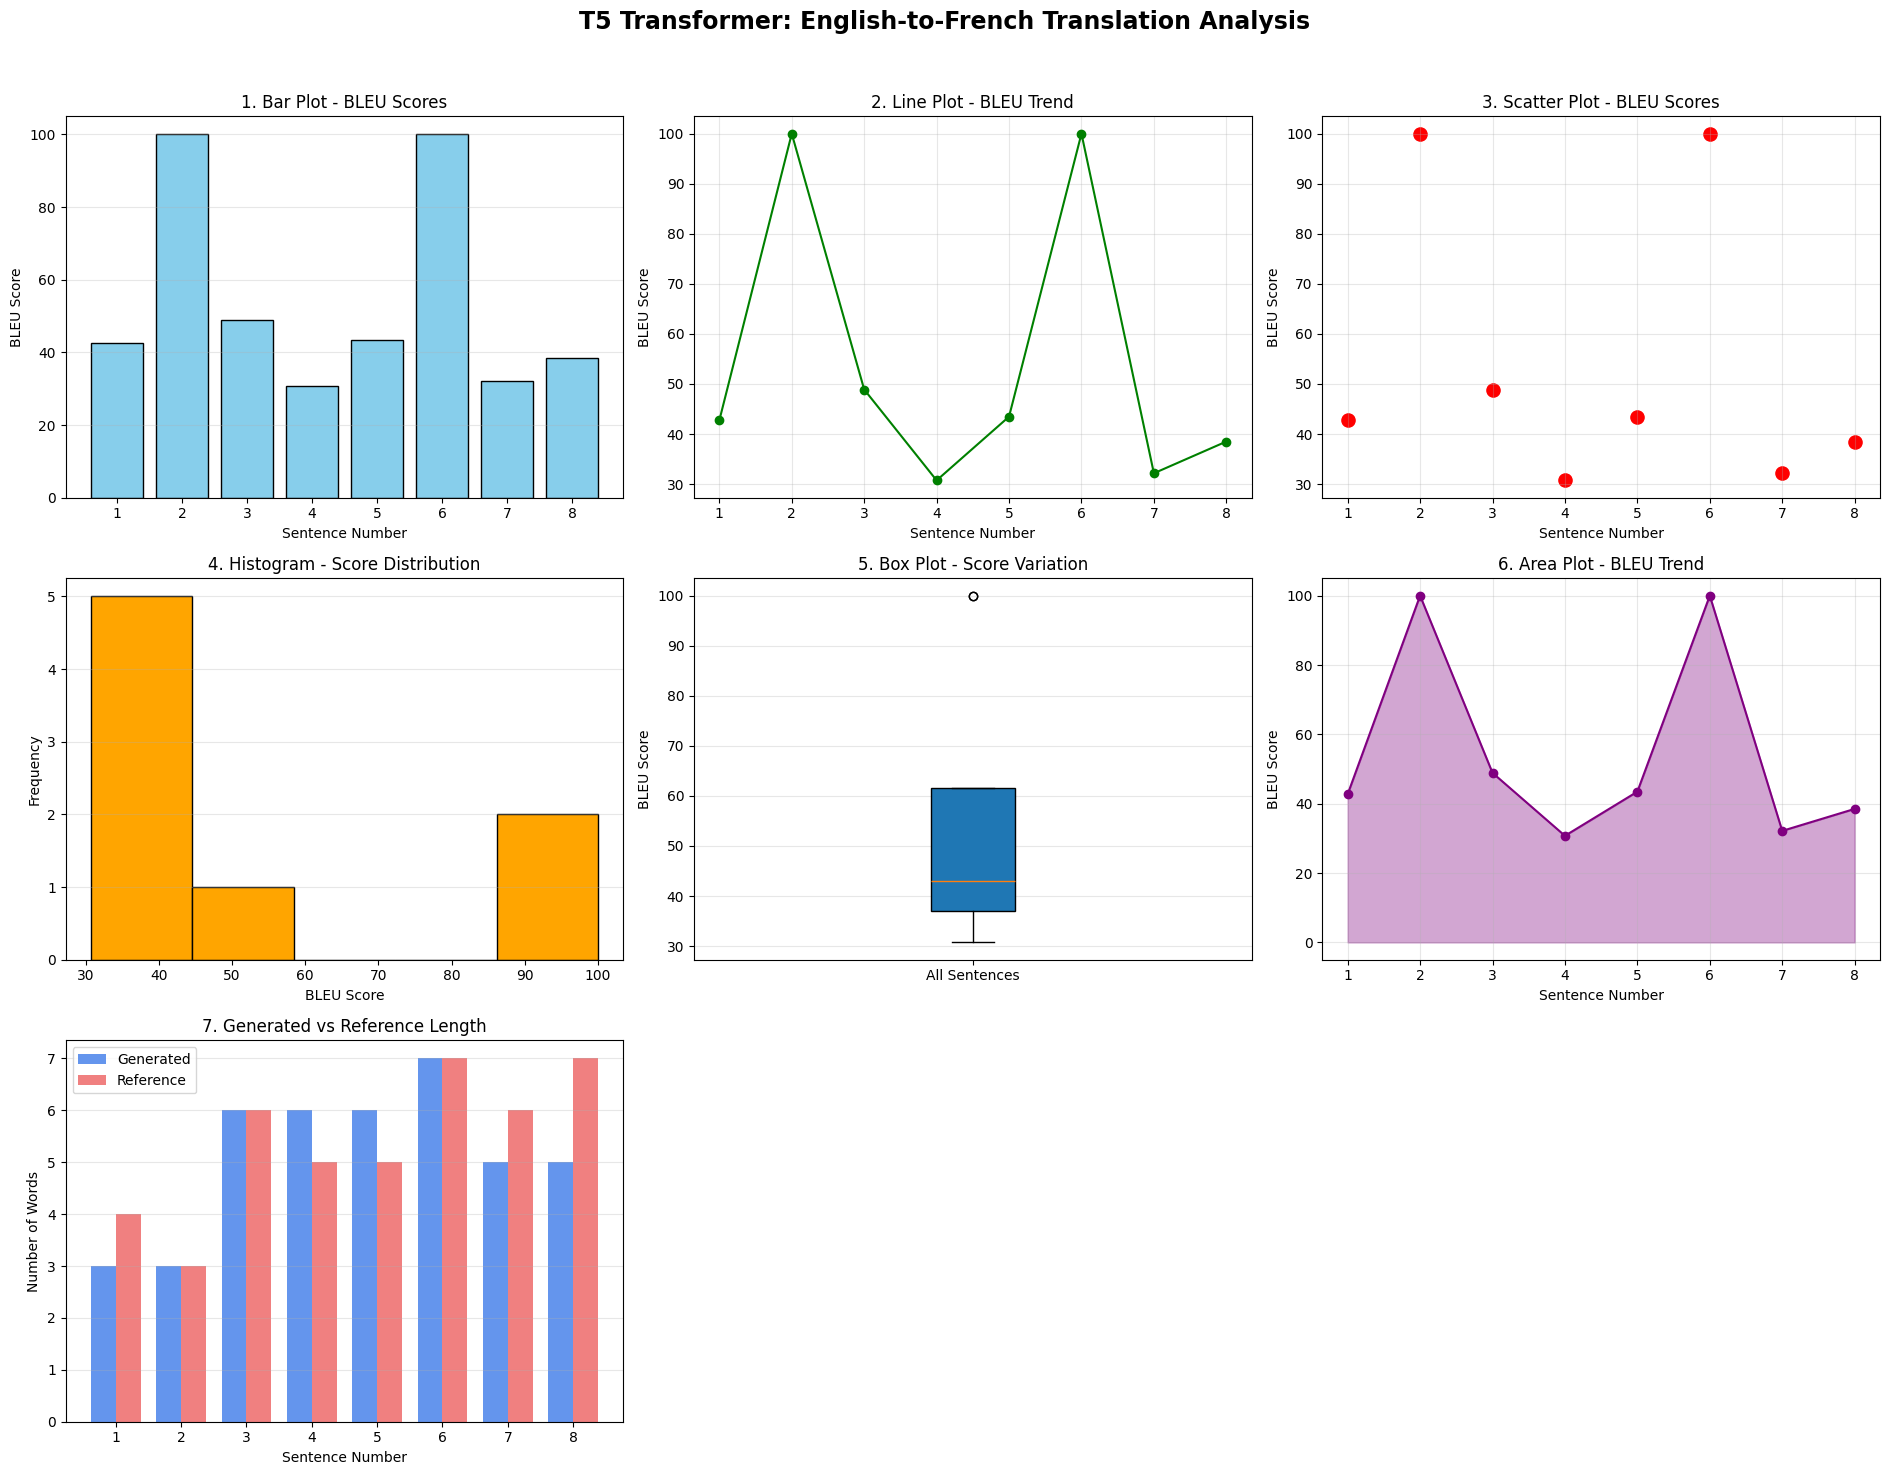


Results saved successfully:
1. experiment5_visualizations.png
2. experiment5_translation_results.csv

AUTOMATIC OBSERVATIONS
The average sentence-level BLEU score is 54.56.
The scores range from 30.74 to 100.00.
The standard deviation is 26.81, indicating the amount of variation among sentence scores.
The highest and lowest scores identify sentences with the greatest and least n-gram overlap with their references.
BLEU measures textual overlap and should not be treated as a complete measure of translation accuracy.

EXPERIMENT 5 EXECUTION COMPLETED.


In [ ]:

# ============================================================
# GENERATIVE AI LABORATORY - EXPERIMENT 5
# DATA VISUALIZATION FOR AI MODELS
# English-to-French Translation using T5 Transformer
# BLEU Score Evaluation and Visualization
# ============================================================

# STEP 1: Install required libraries
%pip install -q transformers torch sacrebleu matplotlib pandas

# STEP 2: Import required libraries
import torch
import pandas as pd
import matplotlib.pyplot as plt
import sacrebleu
import numpy as np

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from IPython.display import display

# STEP 3: Set up the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("GENERATIVE AI LABORATORY - EXPERIMENT 5")
print("T5 ENGLISH-TO-FRENCH TRANSLATION AND DATA VISUALIZATION")
print("=" * 65)
print("Device being used:", device)

# STEP 4: Load the T5-small Transformer model
model_name = "google-t5/t5-small"

print("\nLoading T5 tokenizer and model...")

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
model = model.to(device)
model.eval()

print("T5 model loaded successfully!")

# STEP 5: Define English input sentences
english = [
    "Hello, how are you?",
    "I love artificial intelligence.",
    "The weather is very good today.",
    "I am a student of computer science.",
    "Machine learning is changing the world.",
    "Technology helps people communicate.",
    "The sun rises in the east.",
    "Education is important for everyone."
]

# STEP 6: Define reference French translations
# These are reference translations, not model-generated outputs.
references = [
    "Bonjour, comment allez-vous ?",
    "J'aime l'intelligence artificielle.",
    "Le temps est très beau aujourd'hui.",
    "Je suis étudiante en informatique.",
    "L'apprentissage automatique change le monde.",
    "La technologie aide les gens à communiquer.",
    "Le soleil se lève à l'est.",
    "L'éducation est importante pour tout le monde."
]

# STEP 7: Generate French translations
translations = []
bleu_scores = []

print("\n" + "=" * 65)
print("GENERATED TRANSLATIONS AND SENTENCE-LEVEL BLEU SCORES")
print("=" * 65)

for i, (text, reference) in enumerate(
    zip(english, references), start=1
):
    # T5 uses a task prefix to specify translation
    prompt = "translate English to French: " + text

    # Tokenize the input sentence
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    inputs = {key: value.to(device)
              for key, value in inputs.items()}

    # Generate the French translation
    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=64,
            num_beams=4,
            do_sample=False,
            early_stopping=True
        )

    # Convert generated tokens into readable text
    french = tokenizer.decode(
        output[0],
        skip_special_tokens=True
    ).strip()

    # Calculate sentence-level BLEU score
    score = sacrebleu.sentence_bleu(
    french,
    [reference],
    use_effective_order=True
  ).score

    translations.append(french)
    bleu_scores.append(score)

    print(f"\nSentence {i}")
    print("English    :", text)
    print("Generated  :", french)
    print("Reference  :", reference)
    print("BLEU Score :", round(score, 2))

# STEP 8: Calculate the overall corpus BLEU score
corpus_bleu = sacrebleu.corpus_bleu(
    translations,
    [references]
).score

print("\n" + "=" * 65)
print("OVERALL CORPUS BLEU SCORE:", round(corpus_bleu, 2))
print("=" * 65)

# STEP 9: Create a results table
results_df = pd.DataFrame({
    "Sentence No.": range(1, len(english) + 1),
    "English Input": english,
    "Generated French": translations,
    "Reference French": references,
    "BLEU Score": np.round(bleu_scores, 2),
    "Generated Length": [len(t.split()) for t in translations],
    "Reference Length": [len(r.split()) for r in references]
})

print("\nCOMPLETE TRANSLATION RESULTS TABLE")
display(results_df)

# STEP 10: Calculate statistical measures
scores = np.array(bleu_scores)

average_score = np.mean(scores)
minimum_score = np.min(scores)
maximum_score = np.max(scores)
standard_deviation = np.std(scores)

best_index = int(np.argmax(scores))
worst_index = int(np.argmin(scores))

print("\n" + "=" * 65)
print("BLEU SCORE STATISTICAL ANALYSIS")
print("=" * 65)
print(f"Average BLEU Score      : {average_score:.2f}")
print(f"Minimum BLEU Score      : {minimum_score:.2f}")
print(f"Maximum BLEU Score      : {maximum_score:.2f}")
print(f"Standard Deviation      : {standard_deviation:.2f}")
print(f"Corpus BLEU Score       : {corpus_bleu:.2f}")

print("\nHighest-scoring sentence:")
print("English:", english[best_index])
print("French :", translations[best_index])
print("Score  :", round(scores[best_index], 2))

print("\nLowest-scoring sentence:")
print("English:", english[worst_index])
print("French :", translations[worst_index])
print("Score  :", round(scores[worst_index], 2))

# STEP 11: Prepare data for visualization
x = np.arange(1, len(english) + 1)

# Use a readable figure size for all seven plots
fig, axes = plt.subplots(3, 3, figsize=(19, 15))
axes = axes.flatten()

# PLOT 1: Bar Plot
axes[0].bar(x, scores, color="skyblue", edgecolor="black")
axes[0].set_title("1. Bar Plot - BLEU Scores")
axes[0].set_xlabel("Sentence Number")
axes[0].set_ylabel("BLEU Score")
axes[0].set_xticks(x)
axes[0].grid(axis="y", alpha=0.3)

# PLOT 2: Line Plot
axes[1].plot(x, scores, marker="o", color="green")
axes[1].set_title("2. Line Plot - BLEU Trend")
axes[1].set_xlabel("Sentence Number")
axes[1].set_ylabel("BLEU Score")
axes[1].set_xticks(x)
axes[1].grid(True, alpha=0.3)

# PLOT 3: Scatter Plot
axes[2].scatter(x, scores, color="red", s=90)
axes[2].set_title("3. Scatter Plot - BLEU Scores")
axes[2].set_xlabel("Sentence Number")
axes[2].set_ylabel("BLEU Score")
axes[2].set_xticks(x)
axes[2].grid(True, alpha=0.3)

# PLOT 4: Histogram
axes[3].hist(
    scores,
    bins=min(5, len(scores)),
    color="orange",
    edgecolor="black"
)
axes[3].set_title("4. Histogram - Score Distribution")
axes[3].set_xlabel("BLEU Score")
axes[3].set_ylabel("Frequency")
axes[3].grid(axis="y", alpha=0.3)

# PLOT 5: Box Plot
axes[4].boxplot(scores, patch_artist=True)
axes[4].set_title("5. Box Plot - Score Variation")
axes[4].set_ylabel("BLEU Score")
axes[4].set_xticks([1])
axes[4].set_xticklabels(["All Sentences"])
axes[4].grid(axis="y", alpha=0.3)

# PLOT 6: Area Plot
axes[5].fill_between(x, scores, alpha=0.35, color="purple")
axes[5].plot(x, scores, marker="o", color="purple")
axes[5].set_title("6. Area Plot - BLEU Trend")
axes[5].set_xlabel("Sentence Number")
axes[5].set_ylabel("BLEU Score")
axes[5].set_xticks(x)
axes[5].grid(True, alpha=0.3)

# PLOT 7: Generated vs Reference Sentence Length
generated_lengths = [len(t.split()) for t in translations]
reference_lengths = [len(r.split()) for r in references]

width = 0.38

axes[6].bar(
    x - width / 2,
    generated_lengths,
    width,
    label="Generated",
    color="cornflowerblue"
)
axes[6].bar(
    x + width / 2,
    reference_lengths,
    width,
    label="Reference",
    color="lightcoral"
)

axes[6].set_title("7. Generated vs Reference Length")
axes[6].set_xlabel("Sentence Number")
axes[6].set_ylabel("Number of Words")
axes[6].set_xticks(x)
axes[6].legend()
axes[6].grid(axis="y", alpha=0.3)

# Keep the remaining two subplot spaces empty
axes[7].axis("off")
axes[8].axis("off")

fig.suptitle(
    "T5 Transformer: English-to-French Translation Analysis",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save the visualization for the lab report
plt.savefig(
    "experiment5_visualizations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# STEP 12: Export results to a CSV file
results_df.to_csv("experiment5_translation_results.csv", index=False)

print("\nResults saved successfully:")
print("1. experiment5_visualizations.png")
print("2. experiment5_translation_results.csv")

# STEP 13: Generate a short automatic observation
print("\n" + "=" * 65)
print("AUTOMATIC OBSERVATIONS")
print("=" * 65)

print(
    f"The average sentence-level BLEU score is "
    f"{average_score:.2f}."
)

print(
    f"The scores range from {minimum_score:.2f} "
    f"to {maximum_score:.2f}."
)

print(
    f"The standard deviation is {standard_deviation:.2f}, "
    "indicating the amount of variation among sentence scores."
)

print(
    "The highest and lowest scores identify sentences with "
    "the greatest and least n-gram overlap with their references."
)

print(
    "BLEU measures textual overlap and should not be treated "
    "as a complete measure of translation accuracy."
)

print("\nEXPERIMENT 5 EXECUTION COMPLETED.")
